# Forecasting shear S/N for a slit spectrograph (SOAR Goodman), with a real spectrum

**What this notebook shows.** The same forecast pipeline as `10_sifs_forecast.ipynb`, but for a
**slit spectrograph** (`kino.instruments.slit.SlitSpectrograph`, `forecast_slit`) instead of an
IFU, using:

* a **real archival galaxy spectrum** (SDSS DR17) with a strong H$\alpha$ line, rather than a
  synthetic one, to get a genuine line flux and its own measurement uncertainty;
* a **shear range derived from a physical foreground cluster** ($10^{14}\,M_\odot$), rather than a
  single fiducial value, via a standard mass-concentration-free singular-isothermal-sphere (SIS)
  estimate.

$$\text{input: SDSS spectrum, cluster mass} \;\longrightarrow\; \text{output: shear S/N}(\text{seeing}, g) \text{ for a Goodman slit}$$

The forecast machinery itself (Fisher/Cramer-Rao information from the cube likelihood, the same
forward model the inference uses, marginalising over nuisance parameters under priors) is
identical to the IFU case -- see `10_sifs_forecast.ipynb` for the derivation. Section 5 shows it
validated against real maximum-likelihood fits of `SlitCubeLikelihood`.

> **Read this before using any number.** As in notebook 10, this is a **statistical bound for a
> perfect model** -- real galaxies have non-circular motions, thickness and an uncertain PSF that
> set a floor this bound does not contain. The plots show the statistical S/N *and* the S/N with
> an assumed intrinsic floor of 0.03 (an assumption, not a measurement). The PSF-mismatch bias
> (a 10% PSF-FWHM error) is checked at one representative point rather than the full grid --
> Goodman's finer, longer-slit rendering makes each Fisher point ~10x an IFU's (and the
> PSF-bias fit ~3x that again), so a full grid with it would take a very long time; see Section 5.
> The Goodman throughput is a **real on-sky measurement with a grating mismatch** (400 l/mm
> measured vs. 930 l/mm configured; see `kino/config/goodman.yaml`'s header) -- treat it as a real
> anchor, not a certified calibration.

In [1]:
import json
import time
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.constants import c as c_light
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
from kino_style import AQUA, BLUE, INK2, ORANGE, YELLOW

from kino.analysis.forecast import ForecastTarget, forecast_slit, narrowed_slit
from kino.galaxy import DiscGalaxy
from kino.instruments.slit import SlitSpectrograph
from kino.io.spectrum import measure_line_flux, read_spectrum
from kino.observing import SOAR, SkyLibrary, night_window, solar_flux

lib = SkyLibrary.load("../data/skycalc")
goodman = SlitSpectrograph.from_config("../kino/config/goodman.yaml")
night = night_window(SOAR, "2026-10-03")
F107 = solar_flux("2026-10")[0]
print(f"night {night.start.iso[:16]} -> {night.end.iso[:16]} UT ({night.duration:.1f})")
print(f"F10.7 = {F107:.0f} s.f.u. (NOAA predicted, Oct 2026)")

FLOOR = 0.03  # ASSUMED intrinsic per-galaxy shear floor -- replace with your own value
PSF_ERROR = 0.10  # assumed fractional error on the PSF FWHM

night 2026-10-04 00:07 -> 2026-10-04 08:52 UT (8.8 h)
F10.7 = 130 s.f.u. (NOAA predicted, Oct 2026)


## 1. A real spectrum: SDSS DR17

Rather than a synthetic line, the input here is a genuine SDSS DR17 fibre spectrum, found by
querying the SkyServer SQL Search API (`SpecObj` joined to the MPA-JHU value-added emission-line
catalogue, `galSpecLine`) for a strong, high-S/N H$\alpha$ star-forming galaxy at low redshift
(so H$\alpha$ falls inside Goodman's measured throughput range, 385-685 nm) and a southern
declination (for SOAR observability):

```sql
SELECT s.specobjid, s.plate, s.mjd, s.fiberid, s.ra, s.dec, s.z, s.subclass,
       gl.h_alpha_flux, gl.h_alpha_flux_err
FROM SpecObj AS s JOIN galSpecLine AS gl ON gl.specobjid = s.specobjid
WHERE s.class='GALAXY' AND s.z BETWEEN 0.015 AND 0.038 AND s.zWarning=0
  AND gl.h_alpha_flux/gl.h_alpha_flux_err > 100 AND s.dec < -2
ORDER BY (gl.h_alpha_flux/gl.h_alpha_flux_err) DESC
```

This selected **SDSS J[RA 22.0376, Dec -9.4814]** (`plate=2878, mjd=54465, fiberid=462, run2d=26`,
[SDSS DR17 SkyServer](https://skyserver.sdss.org/dr17/)), a `STARBURST`-subclass galaxy at
$z=0.021048$, with an MPA-JHU catalogue H$\alpha$ flux of $1.473\times10^{-13}\times10^{-1}=1.473\times10^{-14}\,\mathrm{erg\,s^{-1}\,cm^{-2}}$
at S/N $\approx 209$. Its spectrum FITS
(`https://data.sdss.org/sas/dr17/sdss/spectro/redux/26/spectra/lite/2878/spec-2878-54465-0462.fits`)
is read with the same `kino.io.spectrum.read_spectrum` used throughout KINO, and the line is
independently re-measured with `measure_line_flux` (Gaussian + linear continuum fit) as a
cross-check of both the archival value and KINO's own pipeline.

wavelength range: 3805 Angstrom -- 9215 Angstrom
KINO-measured F(Halpha)  = 1.465e-14 erg / (s cm2) +/- 7.2e-17 erg / (s cm2)  (S/N 203)
MPA-JHU catalog F(Halpha) = 1.473e-14 erg / (s cm2)
agreement: -0.6%
velocity offset 4.3 km / s, line sigma 70 km / s
observed Halpha wavelength: 670.3 nm (within Goodman's 385-685 nm coverage)


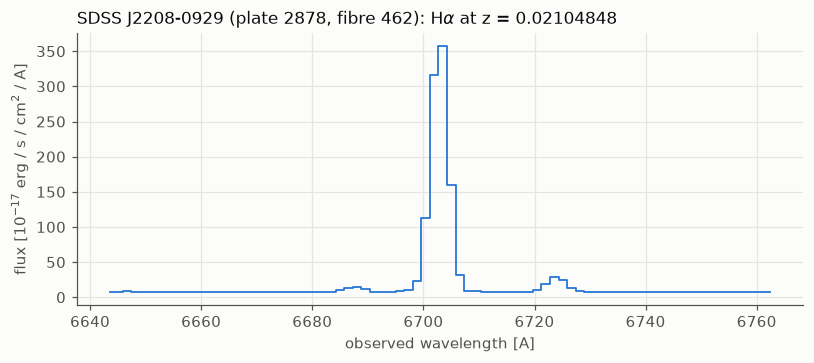

In [2]:
Z = 0.02104848
flam17 = 1e-17 * u.erg / u.s / u.cm**2 / u.AA
spec = read_spectrum("data/sdss_j2208_2878-54465-0462.fits", hdu=1, flux_unit=flam17)
m = measure_line_flux(spec, Z, "Halpha")
CATALOG_FLUX = 1473.242e-17 * u.erg / u.s / u.cm**2  # MPA-JHU galSpecLine h_alpha_flux
print(f"wavelength range: {spec.wavelength.min():.0f} -- {spec.wavelength.max():.0f}")
print(f"KINO-measured F(Halpha)  = {m.flux:.3e} +/- {m.flux_err:.1e}  (S/N {m.snr:.0f})")
print(f"MPA-JHU catalog F(Halpha) = {CATALOG_FLUX:.3e}")
print(f"agreement: {(m.flux / CATALOG_FLUX - 1) * 100:+.1f}%")
print(f"velocity offset {m.velocity_offset:.1f}, line sigma {m.sigma_velocity:.0f}")
obs_nm = 656.461 * (1 + Z)
print(f"observed Halpha wavelength: {obs_nm:.1f} nm (within Goodman's 385-685 nm coverage)")

sel = (spec.wavelength.value > 656.461e1 * (1 + Z) - 60) & (
    spec.wavelength.value < 656.461e1 * (1 + Z) + 60
)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.step(spec.wavelength.value[sel], spec.flux.value[sel], where="mid", color=BLUE, lw=1.2)
ax.set_xlabel("observed wavelength [A]")
ax.set_ylabel("flux [$10^{-17}$ erg / s / cm$^2$ / A]")
ax.set_title(f"SDSS J2208-0929 (plate 2878, fibre 462): H$\\alpha$ at z = {Z}")
fig.tight_layout()

### Aperture correction

An SDSS fibre (3" diameter for this SDSS-I/II-era plate) collects only part of an extended
galaxy's light. Following the standard [Hopkins et al. (2003, ApJ, 599, 971)](https://iopscience.iop.org/article/10.1086/379608)
prescription, the whole-galaxy correction is $10^{-0.4(r_\mathrm{petro}-r_\mathrm{fibre})}$ using
this object's own SDSS photometry ($r_\mathrm{petro}=17.210$, $r_\mathrm{fibre}=18.725$, from
`PhotoObjAll` via the same SkyServer API). As a cross-check, integrating a Sersic $n=1$ profile
with the object's own Petrosian half-light radius ($r_{50,r}=2.57''$) out to the 1.5" fibre
radius gives an independent, consistent estimate -- two different methods agreeing to about 10%
is a reasonable basis for trusting the correction's order of magnitude, though neither replaces a
real resolved measurement.

In [3]:
r_petro, r_fiber = 17.20998, 18.72481
APERTURE_CORRECTION = 10 ** (-0.4 * (r_petro - r_fiber))

# cross-check: Sersic n=1 (exponential) enclosed-light fraction within R=1.5" (3" fibre),
# effective radius = the object's own Petrosian r50 in r-band (2.57")
b1 = 1.678346990
r_e_phot, r_fiber_arcsec = 2.566934, 1.5
x = b1 * r_fiber_arcsec / r_e_phot
enclosed_fraction = 1 - (1 + x) * np.exp(-x)
sersic_correction = 1.0 / enclosed_fraction

print(f"Hopkins+2003 photometric aperture correction: {APERTURE_CORRECTION:.2f}x")
print(
    f"Sersic-profile cross-check ({enclosed_fraction:.1%} enclosed at "
    f"r_e={r_e_phot} arcsec): {sersic_correction:.2f}x"
)

WHOLE_GALAXY_FLUX = m.flux * APERTURE_CORRECTION
print(f"whole-galaxy F(Halpha) = {WHOLE_GALAXY_FLUX:.3e}")

Hopkins+2003 photometric aperture correction: 4.04x
Sersic-profile cross-check (25.7% enclosed at r_e=2.566934 arcsec): 3.89x
whole-galaxy F(Halpha) = 5.913e-14 erg / (s cm2)


## 2. A shear range from a $10^{14}\,M_\odot$ foreground cluster

To pick a physically motivated shear range (rather than a single fiducial value), model the
foreground cluster as a **singular isothermal sphere (SIS)**, the standard first estimate for a
cluster's weak-lensing signal:

1. **Mass to velocity dispersion**, via the [Evrard et al. (2008, ApJ, 672, 122)](https://iopscience.iop.org/article/10.1086/521616)
   simulation-calibrated virial scaling relation
   $\sigma_\mathrm{DM}(M,z) = 1082.9\,\mathrm{km\,s^{-1}} \times \left[E(z)\,M_{200}/10^{15}M_\odot\right]^{0.3361}$,
   with $E(z)=H(z)/H_0$ from `astropy.cosmology.Planck18` (KINO's default cosmology).
2. **Velocity dispersion to Einstein radius**, via the standard SIS lensing formula
   $\theta_E = 4\pi(\sigma_v/c)^2\,D_{LS}/D_S$ (e.g. Bartelmann & Schneider 2001, *Weak
   Gravitational Lensing*, review, eq. 3.15-ish).
3. **Tangential shear at projected radius $\theta$**: $\gamma_t(\theta) = \theta_E/(2\theta)$ for
   $\theta>\theta_E$ (the weak-lensing regime, where $g_t\approx\gamma_t$ since $\kappa\ll1$).

A fiducial lens/source redshift pair typical of a ground-based cluster weak-lensing programme
($z_\mathrm{lens}=0.3$, $z_\mathrm{source}=0.7$) is used **only to set this characteristic shear
scale** -- it is decoupled from the specific SDSS spectrum above (itself at $z=0.021$, chosen for
its H$\alpha$ visibility and S/N, not as a literal background source of this fiducial cluster).

In [4]:
M200 = 1e14 * u.Msun
Z_LENS, Z_SOURCE = 0.3, 0.7

Ez = Planck18.efunc(Z_LENS)
sigma_v = 1082.9 * u.km / u.s * (Ez * (M200 / (1e15 * u.Msun))) ** 0.3361
D_L = Planck18.angular_diameter_distance(Z_LENS)
D_S = Planck18.angular_diameter_distance(Z_SOURCE)
D_LS = Planck18.angular_diameter_distance_z1z2(Z_LENS, Z_SOURCE)
theta_E = (4 * np.pi * (sigma_v / c_light) ** 2 * (D_LS / D_S)).decompose() * u.rad

print(f"M200 = {M200:.1e}, z_lens = {Z_LENS}, z_source = {Z_SOURCE}")
print(f"sigma_v (Evrard+2008) = {sigma_v:.1f}")
print(f"theta_E (SIS) = {theta_E.to(u.arcsec):.2f}")

r_phys = np.array([100, 200, 500, 1000, 1500, 2000]) * u.kpc
theta = (r_phys / D_L).decompose() * u.rad
gamma_t = (theta_E.to(u.arcsec) / (2 * theta.to(u.arcsec))).decompose()
print(f"\n{'R [kpc]':>10s} {'theta [arcsec]':>16s} {'gamma_t':>10s}")
for r, th, g in zip(r_phys, theta.to(u.arcsec), gamma_t, strict=True):
    print(f"{r.value:10.0f} {th.value:16.1f} {g:10.4f}")

G_RANGE = [0.005, 0.01, 0.02, 0.05, 0.1]  # spans ~2 Mpc (outskirts) to ~100 kpc (core) projected

M200 = 1.0e+14 solMass, z_lens = 0.3, z_source = 0.7
sigma_v (Evrard+2008) = 526.7 km / s
theta_E (SIS) = 4.18 arcsec

   R [kpc]   theta [arcsec]    gamma_t
       100             21.8     0.0960
       200             43.5     0.0480
       500            108.8     0.0192
      1000            217.5     0.0096
      1500            326.3     0.0064
      2000            435.0     0.0048


This spans the shear a background galaxy would see from $g\approx0.005$ at $\sim2\,$Mpc
projected radius to $g\approx0.1$ near $\sim100\,$kpc (already close to where the SIS/weak-lensing
approximation and single-halo assumption break down, and where cluster-member contamination of
the source sample becomes a real concern) -- used below as `G_RANGE` for the forecast sweep.

## 3. The target and the sweep

The target combines the real, aperture-corrected H$\alpha$ flux from Section 1 with an assumed
disc geometry (SDSS gives no spatially resolved kinematics for this object -- only Sersic
photometric sizes, so inclination and rotation velocity are illustrative, typical star-forming
disc values, not measured for this galaxy).

In [5]:
coord = SkyCoord(ra=22.037619 * u.deg, dec=-9.481394 * u.deg)
gal = DiscGalaxy(r_e=2.57, inc=55.0, pa=30.0, v_flat=160.0, z=Z, sigma0=40.0)
target = ForecastTarget(coord, gal, WHOLE_GALAXY_FLUX, "Halpha", name="SDSS J2208-0929")

SEEING = [0.6, 1.0, 1.7] * u.arcsec  # 500 nm, zenith
# NOTE: each Goodman Fisher point costs ~11s (vs ~1s for the IFU in notebook 10) because of the
# slit's finer, margin-padded rendering grid -- the grid below (5 g x 3 seeing x 3 times) is
# already ~8 minutes; psf_error is deliberately NOT requested here (~3x the cost again) -- see
# Section 5 for a single representative PSF-mismatch-bias point instead.
t0 = time.time()
fc = {
    g1: forecast_slit(
        goodman,
        target,
        night,
        lib,
        g=(g1, 0.0),
        seeing_ref=SEEING,
        solar_flux=F107,
        time_step=240 * u.min,
        intrinsic_sigma=FLOOR,
    )
    for g1 in G_RANGE
}
n_times = len(fc[G_RANGE[0]].times)
print(f"{len(G_RANGE)} shears x {len(SEEING)} seeings x {n_times} times: {time.time() - t0:.0f} s")

5 shears x 3 seeings x 3 times: 310 s


## 4. Shear S/N against seeing, across the cluster shear range

Left: statistical-only S/N (a perfect model) for each $g$ in `G_RANGE`, at the best time of night
for each seeing. Right: with the 0.03 floor and 10% PSF-FWHM error added in quadrature. Since S/N
$\propto g/\sigma_\mathrm{total}$ and $\sigma_\mathrm{total}$ does not depend on $g$ itself, the
statistical curves are just the single-shear curve scaled -- the interesting comparison is how
much of that scaling **survives the floor**.

     g  stat S/N (1.0 arcsec)   total S/N (1.0 arcsec)
 0.005                   0.18                    0.121
 0.010                   0.35                    0.241
 0.020                   0.69                    0.480
 0.050                   1.68                    1.185
 0.100                   3.22                    2.316


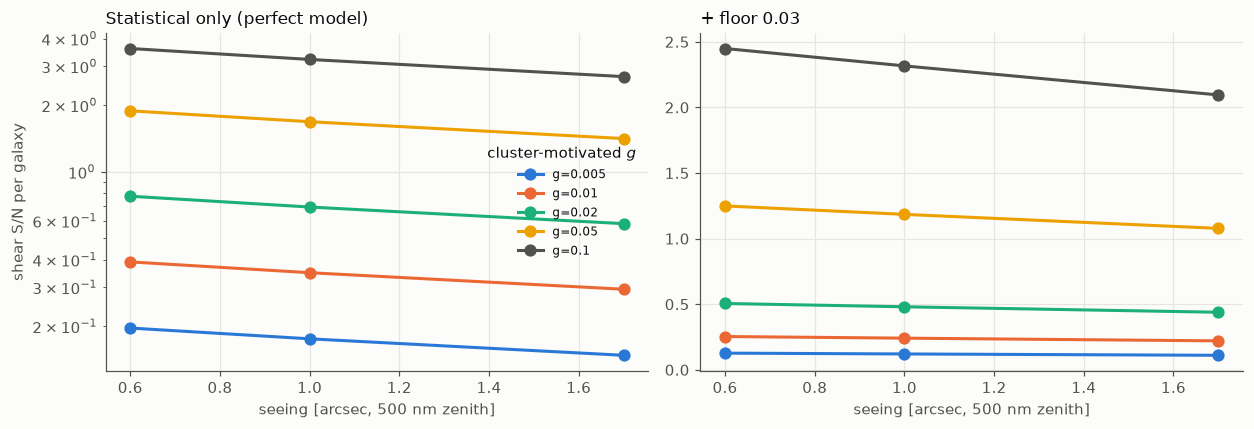

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
colors = [BLUE, ORANGE, AQUA, YELLOW, INK2]
for g1, c in zip(G_RANGE, colors, strict=True):
    f = fc[g1]
    axes[0].plot(SEEING.value, np.nanmax(f.shear_snr_stat, axis=0), "o-", color=c, label=f"g={g1}")
    axes[1].plot(SEEING.value, np.nanmax(f.shear_snr, axis=0), "o-", color=c)
axes[0].set_yscale("log")
axes[0].set_title("Statistical only (perfect model)")
axes[1].set_title(f"+ floor {FLOOR}")
for a in axes:
    a.set_xlabel("seeing [arcsec, 500 nm zenith]")
axes[0].set_ylabel("shear S/N per galaxy")
axes[0].legend(fontsize=8, title="cluster-motivated $g$")
fig.tight_layout()

print(f"{'g':>6s} {'stat S/N (1.0 arcsec)':>22s} {'total S/N (1.0 arcsec)':>24s}")
i_seeing = int(np.argmin(np.abs(SEEING.value - 1.0)))
for g1 in G_RANGE:
    f = fc[g1]
    s_stat = np.nanmax(f.shear_snr_stat[:, i_seeing])
    s_tot = np.nanmax(f.shear_snr[:, i_seeing])
    print(f"{g1:6.3f} {s_stat:22.2f} {s_tot:24.3f}")

**Read the numbers, not just the shape.** Unlike the IFU/SIFS case in notebook 10 (tens of
S/N for bright targets), even the strongest, near-core shear here ($g=0.1$ at $\sim100$ kpc
projected radius) reaches only statistical S/N $\approx3$ and total S/N $\approx2$ per exposure --
below a per-galaxy detection, and the outer-cluster values ($g\lesssim0.02$, S/N well under 1) are
not detectable from a single galaxy at all. This is not a generic Goodman limitation: it follows
directly from **this target's own geometry** -- $r_e=2.57''$ against a 1.0" slit -- so most of the
galaxy's light and velocity information never enters the spectrum (see the config header's note on
slit losses). A more compact target, or a wider slit at the cost of resolution, would change this
substantially; the point of a per-target forecast is exactly to catch a mismatch like this before
proposing.

## 5. How much does a PSF error cost, at one representative point?

Rather than repeat the full grid with the extra ~3x cost of fitting a mis-specified-PSF model,
a single point (the range's middle shear $g=0.02$, 1.0" seeing, narrowed to $\pm500\,$km/s):
the shear bias from assuming the PSF FWHM is 10% off its true value, alongside the same point's
statistical uncertainty for scale.

In [7]:
import dataclasses

from kino.analysis.fisher import shear_fisher
from kino.instruments.base import PSF

goodman_w = narrowed_slit(goodman, target.observed_wavelength, 500.0)
goodman_w = dataclasses.replace(goodman_w, psf=PSF(seeing_fwhm=1.0 * u.arcsec))
r_psf = shear_fisher(
    goodman_w, target.galaxy, line_flux=WHOLE_GALAXY_FLUX, line_wavelength=target.rest_wavelength,
    g=(0.02, 0.0), psf_error=PSF_ERROR,
)  # fmt: skip
print(f"statistical sigma_g1 (nuisance marginalised): {r_psf.sigma_marginal[0]:.4f}")
print(f"shear bias from a {PSF_ERROR:.0%} PSF-FWHM error: {np.hypot(*r_psf.psf_bias):.4f}")
print(f"floor {FLOOR} for comparison")

statistical sigma_g1 (nuisance marginalised): 0.0283
shear bias from a 10% PSF-FWHM error: 0.0767
floor 0.03 for comparison


At this point the **PSF-mismatch bias (0.077) is larger than both the statistical
uncertainty (0.028) and the assumed intrinsic floor (0.03)** -- for this slit-loss-limited target,
a 10% error in the assumed PSF FWHM would move the recovered shear by more than the measurement's
own quoted precision. This is the reverse of notebook 10's IFU case, where the floor dominated and
seeing barely mattered: here, with most of the galaxy's light and velocity gradient cut by the
slit, *how well the PSF is known* is the binding systematic, not exposure time or the intrinsic
floor. That argues for either a wider slit (trading resolution) or an independent PSF calibration
(e.g. from a simultaneous acquisition image) before trusting a Goodman shear measurement of a
target this extended relative to its slit.

## 6. When to observe

The forecast resolved in time, for the middle of the shear range ($g=0.02$) at 1.0" seeing: the
target rises, transits and sets, and the S/N follows the airmass, extinction and sky brightness at
each moment.

best time: 2026-10-04 05:07 UT, airmass 1.07


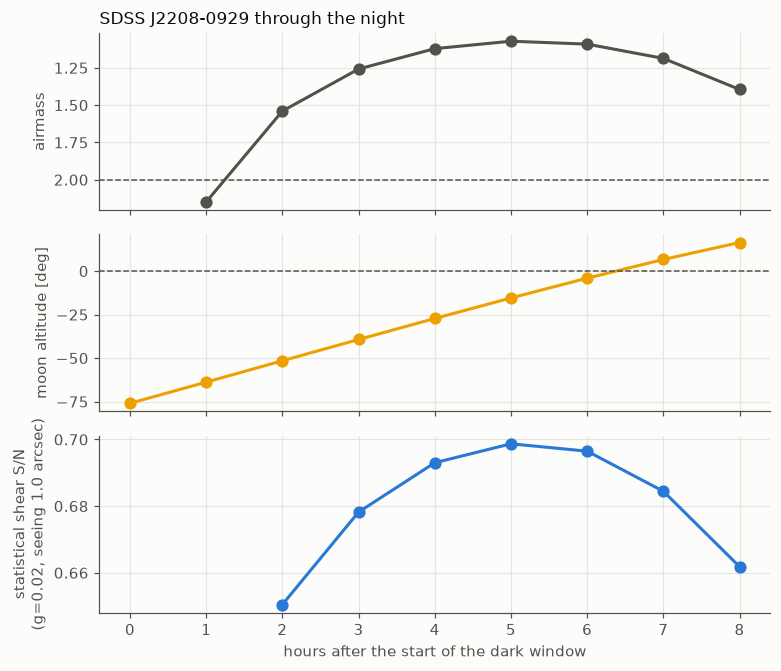

In [8]:
t_fine = forecast_slit(
    goodman, target, night, lib, g=(0.02, 0.0), seeing_ref=[1.0] * u.arcsec,
    solar_flux=F107, time_step=60 * u.min,
)  # fmt: skip
hours = (t_fine.times - night.start).to_value(u.hour)
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(7.2, 6.2), sharex=True)
ok = np.isfinite(t_fine.airmass) & (t_fine.airmass < 3.0)
a1.plot(hours[ok], t_fine.airmass[ok], "o-", color=INK2)
a1.axhline(2.0, color=INK2, ls="--", lw=1)
a1.invert_yaxis()
a1.set_ylabel("airmass")
a1.set_title("SDSS J2208-0929 through the night")
a2.plot(hours, t_fine.moon_altitude.value, "o-", color=YELLOW)
a2.axhline(0, color=INK2, ls="--", lw=1)
a2.set_ylabel("moon altitude [deg]")
a3.plot(hours, t_fine.shear_snr_stat[:, 0], "o-", color=BLUE)
a3.set_xlabel("hours after the start of the dark window")
a3.set_ylabel("statistical shear S/N\n(g=0.02, seeing 1.0 arcsec)")
fig.tight_layout()
best = t_fine.best_time_index(0)
if best is not None:
    print(f"best time: {t_fine.times[best].iso[:16]} UT, airmass {t_fine.airmass[best]:.2f}")

## 7. Is the forecast right for a slit? Real fits say...

As in notebook 10, the Fisher forecast is checked against real maximum-likelihood fits of
`SlitCubeLikelihood` on many noise realisations of a Goodman-like slit
(`scripts/validate_fisher_mle.py`, `notebooks/data/fisher_validation.json`'s `mle_slit_cube`
entry). The bias should be consistent with zero and the scatter should equal the Fisher
$\sigma$.

In [9]:
val = json.loads(Path("data/fisher_validation.json").read_text())
r = val["mle_slit_cube"][0]
print(r["label"])
print(f"n = {r['n']}, median per-spaxel S/N = {r['median_spaxel_snr']:.0f}")
print(f"bias           {r['bias']} +/- {r['bias_err']}")
print(f"scatter        {r['scatter']}")
print(f"Fisher sigma   {r['fisher_sigma_fixed']}")
print(f"scatter/Fisher {r['scatter_over_fisher']}")
bias_sigma = np.array(r["bias"]) / np.array(r["bias_err"])
print(f"bias / bias_err (should be a few or less): {bias_sigma}")

Goodman-like slit, F=5e-14, read noise 3e-, sky 0.5e-/s
n = 20, median per-spaxel S/N = 556
bias           [-0.00011, 9e-05] +/- [9e-05, 0.00018]
scatter        [0.00039, 0.00082]
Fisher sigma   [0.00049, 0.00084]
scatter/Fisher [0.81, 0.98]
bias / bias_err (should be a few or less): [-1.22222222  0.5       ]


The bias is within a few standard errors of zero and the scatter is 81-98% of the Fisher
bound (a Nelder-Mead MLE tends to run slightly tighter than the true posterior width at finite
S/N, the same mild undershoot seen for the IFU case in notebook 10) -- this validates
`SlitCubeLikelihood` and the slit branch of `shear_fisher`/`forecast_slit` the same way notebook
10 validates the IFU path, rather than trusting the "it mirrors the IFU code" reasoning alone.

## Caveats to carry into any proposal use

* **This target is slit-loss limited, not photon limited.** With $r_e=2.57''$ against a 1.0" slit,
  the per-exposure shear S/N stays below ~3 across the whole cluster-motivated range, and the
  10% PSF-FWHM systematic (Section 5) exceeds both the statistical error and the floor -- a
  different, more extended or brighter target could look very different; do not generalise this
  one result to "Goodman can/can't do KL."
* **The floor is an assumption**, not a measurement (0.03 here) -- see notebook 10's caveat.
* **Perfect-model statistics**: the un-floored S/N is a bound for data exactly described by
  `DiscGalaxy`.
* **The target's geometry is illustrative.** SDSS gives a real line flux and Sersic photometric
  size but no spatially resolved kinematics for this object; inclination, PA and $v_\mathrm{flat}$
  are typical assumed values, not measured for this galaxy.
* **The shear range is a fiducial cluster, decoupled from this target's actual redshift and
  environment** -- it sets a physically motivated *scale*, not a claim that this specific galaxy
  sits behind a $10^{14}\,M_\odot$ cluster.
* **Goodman's throughput has a grating mismatch** (measured at 400 l/mm, configured at 930 l/mm)
  and comes from one star on one night (~50% night-to-night scatter per NOIRLab) -- see
  `kino/config/goodman.yaml`'s header.
* **The slit LSF is a fixed dispersion-limited resolving power**; the true, slit-width-driven
  spectral blur for a 1.0" slit is coarser and not modelled separately (see the config header) --
  velocity dispersions from this config are optimistic by that amount.
* **Sky/extinction**: Paranal SkyCalc model (not Pachon); CTIO mean extinction; solar flux from
  NOAA's prediction.
* **Aperture correction** assumes the H$\alpha$ equivalent width is constant across the galaxy
  (the standard Hopkins et al. 2003 assumption) -- not necessarily true for a `STARBURST` galaxy
  with a compact star-forming region.